### From raw data to PILOT: COVID-19 (COMBAT) blood data

<div class="alert alert-block alert-info">
<b>PILOT from scratch</b>

The other tutorials start from data that are already processed. Here we start from the raw counts and show every step:

1. quality control (QC) of the cells, genes and samples,
2. normalization, highly variable genes and PCA,
3. batch correction with Harmony, neighbors, UMAP and Leiden clustering,
4. PILOT: Wasserstein distances, trajectory, principal graph and cell type importance,
5. the clinical variables of the patients on the trajectory.

We use the blood single-cell data of the COMBAT consortium (COVID-19 patients and healthy volunteers). Download the h5ad file of the full dataset from [CELLxGENE](https://cellxgene.cziscience.com/collections/8f126edf-5405-4731-8374-b5ce11f53e82) (*"COMBAT single-cell atlas"*, 836,148 cells), name it `covid_COMBAT.h5ad` and place it in the _Datasets_ folder.

This dataset is large: the steps below need a computer with about 200 GB of memory (or run them on a compute cluster).
</div>

In [ ]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import pilotpy as pl

##### Reading the data

In [ ]:
adata = sc.read_h5ad('Datasets/covid_COMBAT.h5ad')
adata

AnnData object with n_obs × n_vars = 836148 × 36306
    obs: 'GEX_region', 'cluster', 'cluster_source', 'minor_subset', 'minor_subset_source', 'major_subset', 'major_subset_source', 'cell_type_source', 'scRNASeq_sample_ID', 'QC_ngenes', 'QC_total_UMI', 'QC_pct_mitochondrial', 'QC_scrub_doublet_scores', 'TCR_clone_count', 'TCR_clone_proportion', 'BCR_total_mut_HC', 'BCR_clonal_abundance_HC', 'BCR_total_mut_LC', 'assay_ontology_term_id', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'cell_type_original', 'donor_id', 'Source', 'Age', 'BMI', 'Hospitalstay', 'Death28', 'Institute', 'PreExistingHeartDisease', 'PreExistingLungDisease', 'PreExistingKidneyDisease', 'PreExistingDiabetes', 'PreExistingHypertension', 'PreExistingImmunocompromised', 'Smoking', 'Symptomatic', 'Requiredvasoactive', 'SARSCoV2PCR', 'Outcome', 'TimeSinceOnset', 'sex_ontology_term_id', 'development_stage_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'suspension_type

##### Selecting the samples:
<div class="alert alert-block alert-info">
The data contain several cohorts (`Source`). We keep the healthy volunteers (HV) and the COVID-19 patients with mild, severe and critical disease, and remove the other cohorts (sepsis, influenza, health care workers and the low-density neutrophil samples).

Each sample (`scRNASeq_sample_ID`) is one blood sample of one patient; some patients were sampled more than once. PILOT treats each sample as one point of the trajectory.

We make two status columns:

- `group2`: HV or COVID,
- `group4`: HV, COVID_MILD, COVID_SEV or COVID_CRIT.
</div>

In [ ]:
keep = ['HV', 'COVID_MILD', 'COVID_SEV', 'COVID_CRIT']
adata = adata[adata.obs['Source'].isin(keep)].copy()
for col in adata.obs.columns:
    if hasattr(adata.obs[col], 'cat'):
        adata.obs[col] = adata.obs[col].cat.remove_unused_categories()

adata.obs['group2'] = np.where(adata.obs['Source'] == 'HV', 'HV', 'COVID')
adata.obs['group4'] = pd.Categorical(adata.obs['Source'].astype(str), categories = keep)

print(adata.n_obs, 'cells')
adata.obs.groupby('group4', observed = True)['scRNASeq_sample_ID'].nunique().to_frame('samples')

548404 cells

,samples
group4,
HV,10
COVID_MILD,18
COVID_SEV,41
COVID_CRIT,19


##### Raw counts and gene names:
<div class="alert alert-block alert-info">
In CELLxGENE files, `adata.X` is already normalized and the raw counts are in `adata.raw`. QC and normalization need the raw counts, so we use them. We also use the gene symbols (`feature_name`) as gene names.
</div>

In [ ]:
adata = sc.AnnData(X = adata.raw.X, obs = adata.obs, var = adata.raw.var, obsm = adata.obsm)
adata.var_names = adata.var['feature_name'].astype(str)
adata.var_names_make_unique()
print(adata.X[:5, :].sum(axis = 1).ravel())   # raw counts: whole numbers
adata

[[2825. 3253. 1999. 3176.  886.]]

AnnData object with n_obs × n_vars = 548404 × 36306
    obs: 'GEX_region', 'cluster', 'cluster_source', 'minor_subset', 'minor_subset_source', 'major_subset', 'major_subset_source', 'cell_type_source', 'scRNASeq_sample_ID', 'QC_ngenes', 'QC_total_UMI', 'QC_pct_mitochondrial', 'QC_scrub_doublet_scores', 'TCR_clone_count', 'TCR_clone_proportion', 'BCR_total_mut_HC', 'BCR_clonal_abundance_HC', 'BCR_total_mut_LC', 'assay_ontology_term_id', 'disease_ontology_term_id', 'tissue_ontology_term_id', 'cell_type_ontology_term_id', 'cell_type_original', 'donor_id', 'Source', 'Age', 'BMI', 'Hospitalstay', 'Death28', 'Institute', 'PreExistingHeartDisease', 'PreExistingLungDisease', 'PreExistingKidneyDisease', 'PreExistingDiabetes', 'PreExistingHypertension', 'PreExistingImmunocompromised', 'Smoking', 'Symptomatic', 'Requiredvasoactive', 'SARSCoV2PCR', 'Outcome', 'TimeSinceOnset', 'sex_ontology_term_id', 'development_stage_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'suspension_type

##### Quality control of the cells:
<div class="alert alert-block alert-info">
For each cell we compute:

- `n_genes_by_counts`: number of detected genes,
- `total_counts`: number of counts (UMIs),
- `pct_counts_mt`: percentage of counts from mitochondrial genes (high values: damaged or dying cells).

Cells with very few genes are empty droplets or broken cells; cells with very many genes or counts are often doublets (two cells in one droplet).
</div>

In [ ]:
adata.var['mt'] = adata.var_names.str.startswith('MT-')
adata.var['ribo'] = adata.var_names.str.startswith(('RPS', 'RPL'))
sc.pp.calculate_qc_metrics(adata, qc_vars = ['mt', 'ribo'], percent_top = None, log1p = False, inplace = True)
adata.obs[['n_genes_by_counts', 'total_counts', 'pct_counts_mt']].describe().round(1)

,n_genes_by_counts,total_counts,pct_counts_mt
count,548404.0,548404.0,548404.0
mean,1368.6,4523.9,2.6
std,647.0,4331.5,1.6
min,301.0,352.0,0.0
25%,988.0,2562.0,1.4
50%,1245.0,3586.0,2.2
75%,1565.0,4937.0,3.3
max,7055.0,91073.0,12.1


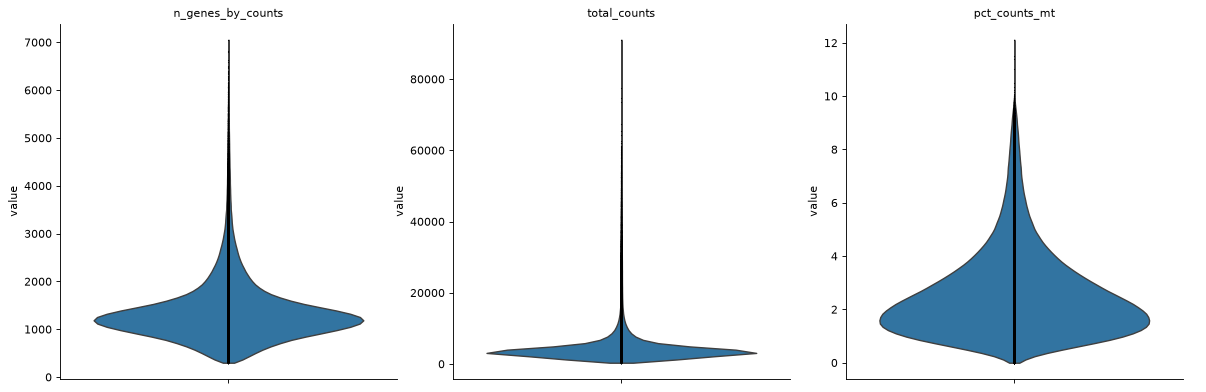

In [ ]:
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'],
             jitter = False, multi_panel = True)

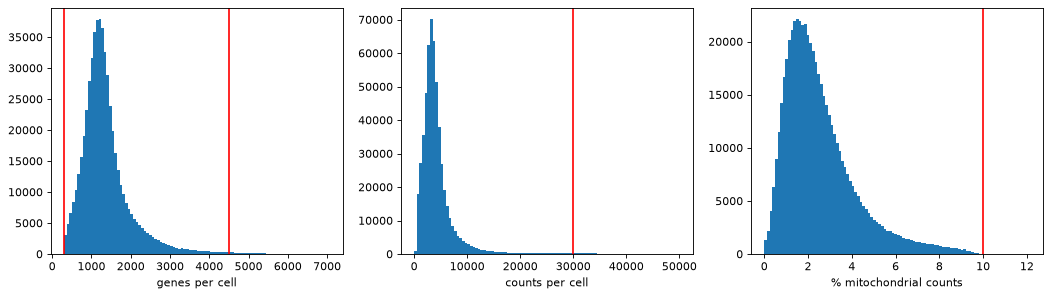

In [ ]:
fig, axes = plt.subplots(1, 3, figsize = (16, 4))
axes[0].hist(adata.obs['n_genes_by_counts'], bins = 100)
axes[0].axvline(300, color = 'red'); axes[0].axvline(4500, color = 'red')
axes[0].set_xlabel('genes per cell')
axes[1].hist(adata.obs['total_counts'], bins = 100, range = (0, 50000))
axes[1].axvline(30000, color = 'red')
axes[1].set_xlabel('counts per cell')
axes[2].hist(adata.obs['pct_counts_mt'], bins = 100)
axes[2].axvline(10, color = 'red')
axes[2].set_xlabel('% mitochondrial counts')
plt.show()

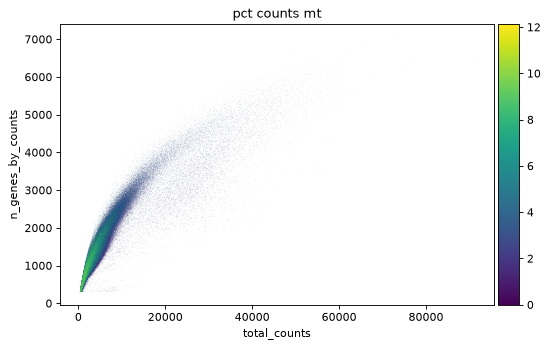

In [ ]:
sc.pl.scatter(adata, x = 'total_counts', y = 'n_genes_by_counts', color = 'pct_counts_mt')

##### Filtering the cells:
<div class="alert alert-block alert-info">
From the plots above we choose the thresholds (red lines):

- 300 to 4,500 detected genes,
- at most 30,000 counts,
- less than 10% mitochondrial counts.

The thresholds depend on the data and the technology; always look at the plots of your own data first.
</div>

In [ ]:
n_before = adata.n_obs
adata = adata[(adata.obs['n_genes_by_counts'] >= 300) &
              (adata.obs['n_genes_by_counts'] <= 4500) &
              (adata.obs['total_counts'] <= 30000) &
              (adata.obs['pct_counts_mt'] < 10)].copy()
print(f'{n_before - adata.n_obs} cells removed, {adata.n_obs} cells left')

4295 cells removed, 544109 cells left

##### Doublets and cells without a cell type:
<div class="alert alert-block alert-info">
The data provide a doublet score for every cell (`QC_scrub_doublet_scores`, computed with Scrublet). We remove cells with a high score. You can also compute the scores yourself with `sc.pp.scrublet(adata, batch_key = 'scRNASeq_sample_ID')`.

The annotation of the authors has the cell type `blood cell` for cells that could not be annotated (most of them are doublets). PILOT compares the cell types between the samples, so we remove these cells as well.
</div>

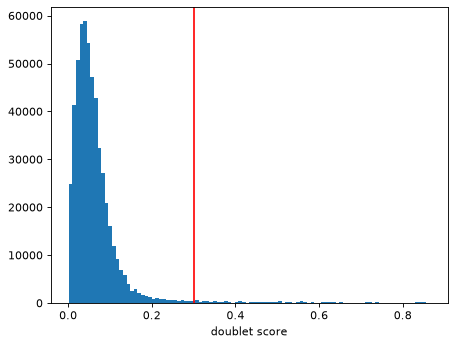

In [ ]:
plt.hist(adata.obs['QC_scrub_doublet_scores'], bins = 100)
plt.axvline(0.3, color = 'red')
plt.xlabel('doublet score')
plt.show()

In [ ]:
n_before = adata.n_obs
adata = adata[(adata.obs['QC_scrub_doublet_scores'] < 0.3) &
              (adata.obs['cell_type'] != 'blood cell')].copy()
adata.obs['cell_type'] = adata.obs['cell_type'].cat.remove_unused_categories()
print(f'{n_before - adata.n_obs} cells removed, {adata.n_obs} cells left')

37330 cells removed, 506779 cells left

##### Quality control of the genes and the samples:
<div class="alert alert-block alert-info">
Genes that are found in very few cells carry no information; we keep genes detected in at least 20 cells.

A sample with very few cells gives unreliable cell type proportions, so we remove samples with fewer than 500 cells.
</div>

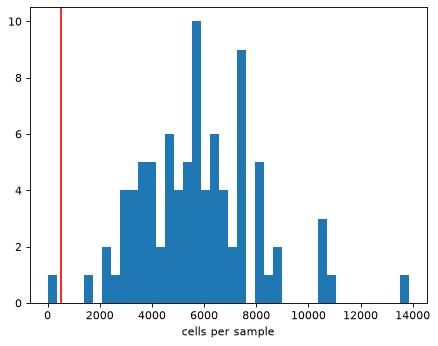

In [ ]:
sc.pp.filter_genes(adata, min_cells = 20)
cells_per_sample = adata.obs['scRNASeq_sample_ID'].value_counts()
plt.hist(cells_per_sample, bins = 40)
plt.axvline(500, color = 'red')
plt.xlabel('cells per sample')
plt.show()

In [ ]:
small = cells_per_sample[cells_per_sample < 500].index
adata = adata[~adata.obs['scRNASeq_sample_ID'].isin(small)].copy()
for col in adata.obs.columns:
    if hasattr(adata.obs[col], 'cat'):
        adata.obs[col] = adata.obs[col].cat.remove_unused_categories()
print('removed samples:', list(small))
print(adata.n_obs, 'cells,', adata.n_vars, 'genes')
adata.obs.groupby('group4', observed = True)['scRNASeq_sample_ID'].nunique().to_frame('samples')

removed samples: ['S00030-Ja003E-PBCa']
506771 cells, 22654 genes

,samples
group4,
HV,10
COVID_MILD,18
COVID_SEV,41
COVID_CRIT,18


##### Normalization and highly variable genes:
<div class="alert alert-block alert-info">
The standard scanpy steps:

1. keep the raw counts in `adata.layers['counts']`,
2. scale every cell to 10,000 counts and take the logarithm,
3. find the 2,000 most variable genes (computed per sample, so that genes that only differ between samples are not chosen).
</div>

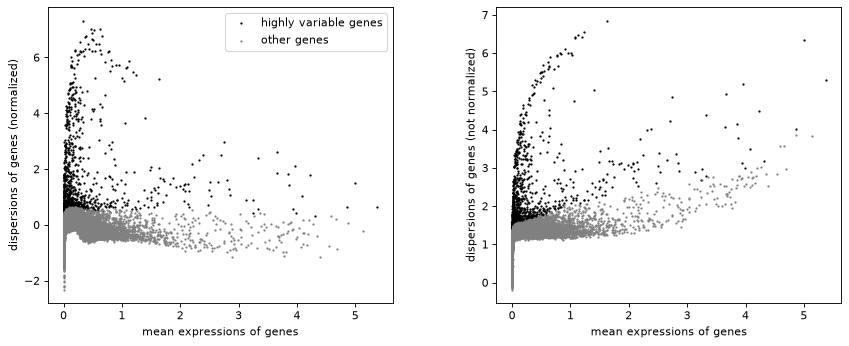

In [ ]:
adata.layers['counts'] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum = 1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes = 2000, batch_key = 'scRNASeq_sample_ID')
sc.pl.highly_variable_genes(adata)

##### PCA:
<div class="alert alert-block alert-info">
The PCA is computed on the highly variable genes, after scaling each gene to mean 0 and variance 1 (values above 10 are clipped). We keep 50 components. The plot shows how much variance each component explains.
</div>

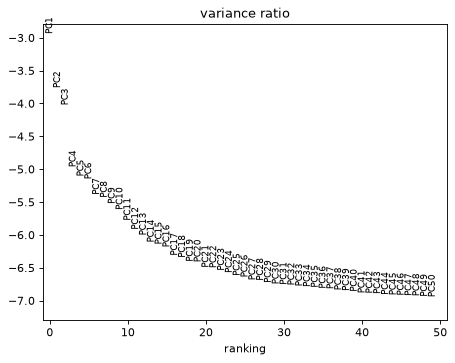

In [ ]:
adata_hvg = adata[:, adata.var['highly_variable']].copy()
sc.pp.scale(adata_hvg, max_value = 10)
sc.tl.pca(adata_hvg, n_comps = 50)
adata.obsm['X_pca'] = adata_hvg.obsm['X_pca']
adata.uns['pca'] = adata_hvg.uns['pca']
del adata_hvg
sc.pl.pca_variance_ratio(adata, n_pcs = 50, log = True)

##### Batch correction with Harmony:
<div class="alert alert-block alert-info">
The samples were processed in different runs, which can shift all cells of a sample a little (batch effect). Harmony corrects the PCA so that the same cell types of different samples overlap. We correct per sample. The result is stored in `adata.obsm['X_pca_harmony']`, which we give to PILOT.

Harmony needs the package `harmonypy` (`pip install harmonypy`). We call it directly (`sc.external.pp.harmony_integrate` does the same, but fails with some versions of harmonypy).
</div>

In [ ]:
import harmonypy as hm
harmony = hm.run_harmony(adata.obsm['X_pca'], adata.obs, 'scRNASeq_sample_ID', random_state = 0, verbose = False)
corrected = np.asarray(harmony.Z_corr)
# depending on the harmonypy version the result is (components x cells) or (cells x components)
adata.obsm['X_pca_harmony'] = corrected.T if corrected.shape[0] != adata.n_obs else corrected
adata.obsm['X_pca_harmony'].shape

(506771, 50)

##### Neighbors, UMAP and Leiden clustering:
<div class="alert alert-block alert-info">
From the corrected PCA we build the neighbor graph of the cells, the UMAP and the Leiden clusters. If your data have no cell type annotation, the Leiden clusters (after annotating them with marker genes) can be used as cell types for PILOT. This dataset has the annotation of the authors (`cell_type`), which we use for PILOT; the Leiden clusters agree well with it.

Note: we compute the neighbors with scikit-learn (`KNeighborsTransformer`, exact and using all CPU cores). With the newest versions of scanpy (1.11.5) and pynndescent (0.7), the default `sc.pp.neighbors(adata, use_rep = 'X_pca_harmony')` fails for data with more than 4,096 cells; with older versions both give the same result.
</div>

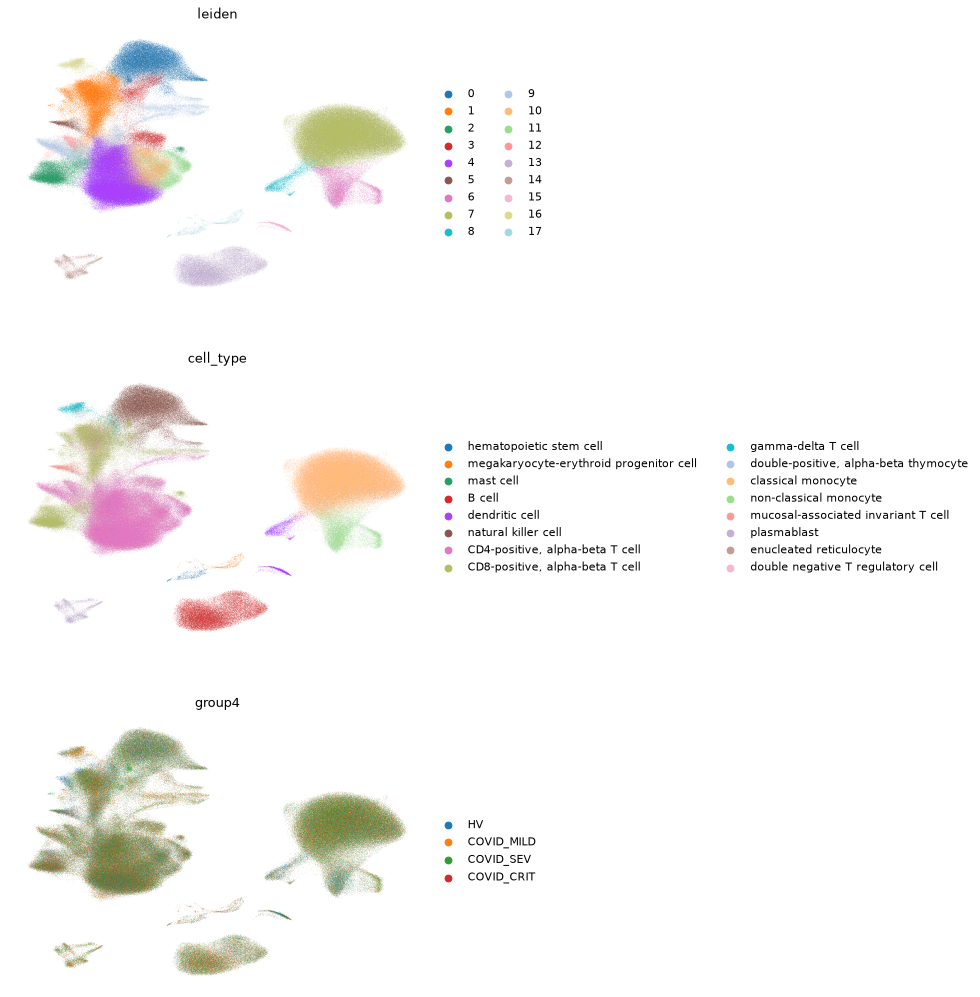

In [ ]:
from sklearn.neighbors import KNeighborsTransformer
sc.pp.neighbors(adata, use_rep = 'X_pca_harmony',
                transformer = KNeighborsTransformer(n_neighbors = 15, n_jobs = -1))
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution = 0.5, flavor = 'igraph', n_iterations = 2)
sc.pl.umap(adata, color = ['leiden', 'cell_type', 'group4'], ncols = 1, frameon = False)

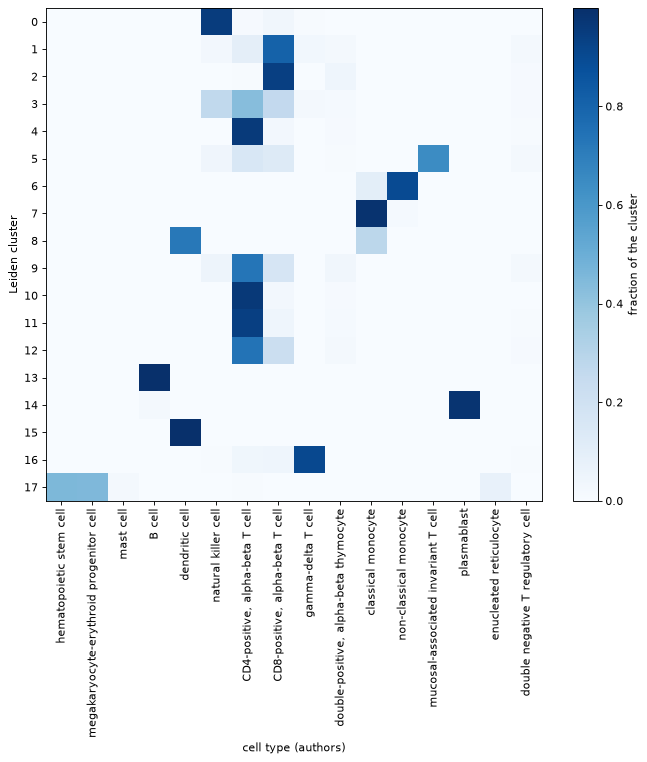

In [ ]:
overlap = pd.crosstab(adata.obs['leiden'], adata.obs['cell_type'], normalize = 'index')
plt.figure(figsize = (10, 8))
plt.imshow(overlap.values, cmap = 'Blues', aspect = 'auto')
plt.xticks(range(overlap.shape[1]), overlap.columns, rotation = 90)
plt.yticks(range(overlap.shape[0]), overlap.index)
plt.xlabel('cell type (authors)'); plt.ylabel('Leiden cluster')
plt.colorbar(label = 'fraction of the cluster')
plt.show()

##### PILOT: Wasserstein distances (HV vs COVID):
<div class="alert alert-block alert-info">
Now the data are ready for PILOT. We give:

- `emb_matrix = 'X_pca_harmony'`: the corrected PCA,
- `clusters_col = 'cell_type'`: the cell types,
- `sample_col = 'scRNASeq_sample_ID'`: the samples,
- `status = 'group2'`: HV or COVID (only used for the colors and the root of the trajectory).

See the [Myocardial Infarction tutorial](https://pilot.readthedocs.io/en/latest/Myocardial_infarction.html) for all parameters.
</div>

In [ ]:
pl.tl.wasserstein_distance(
    adata,
    emb_matrix = 'X_pca_harmony',
    clusters_col = 'cell_type',
    sample_col = 'scRNASeq_sample_ID',
    status = 'group2',
    )

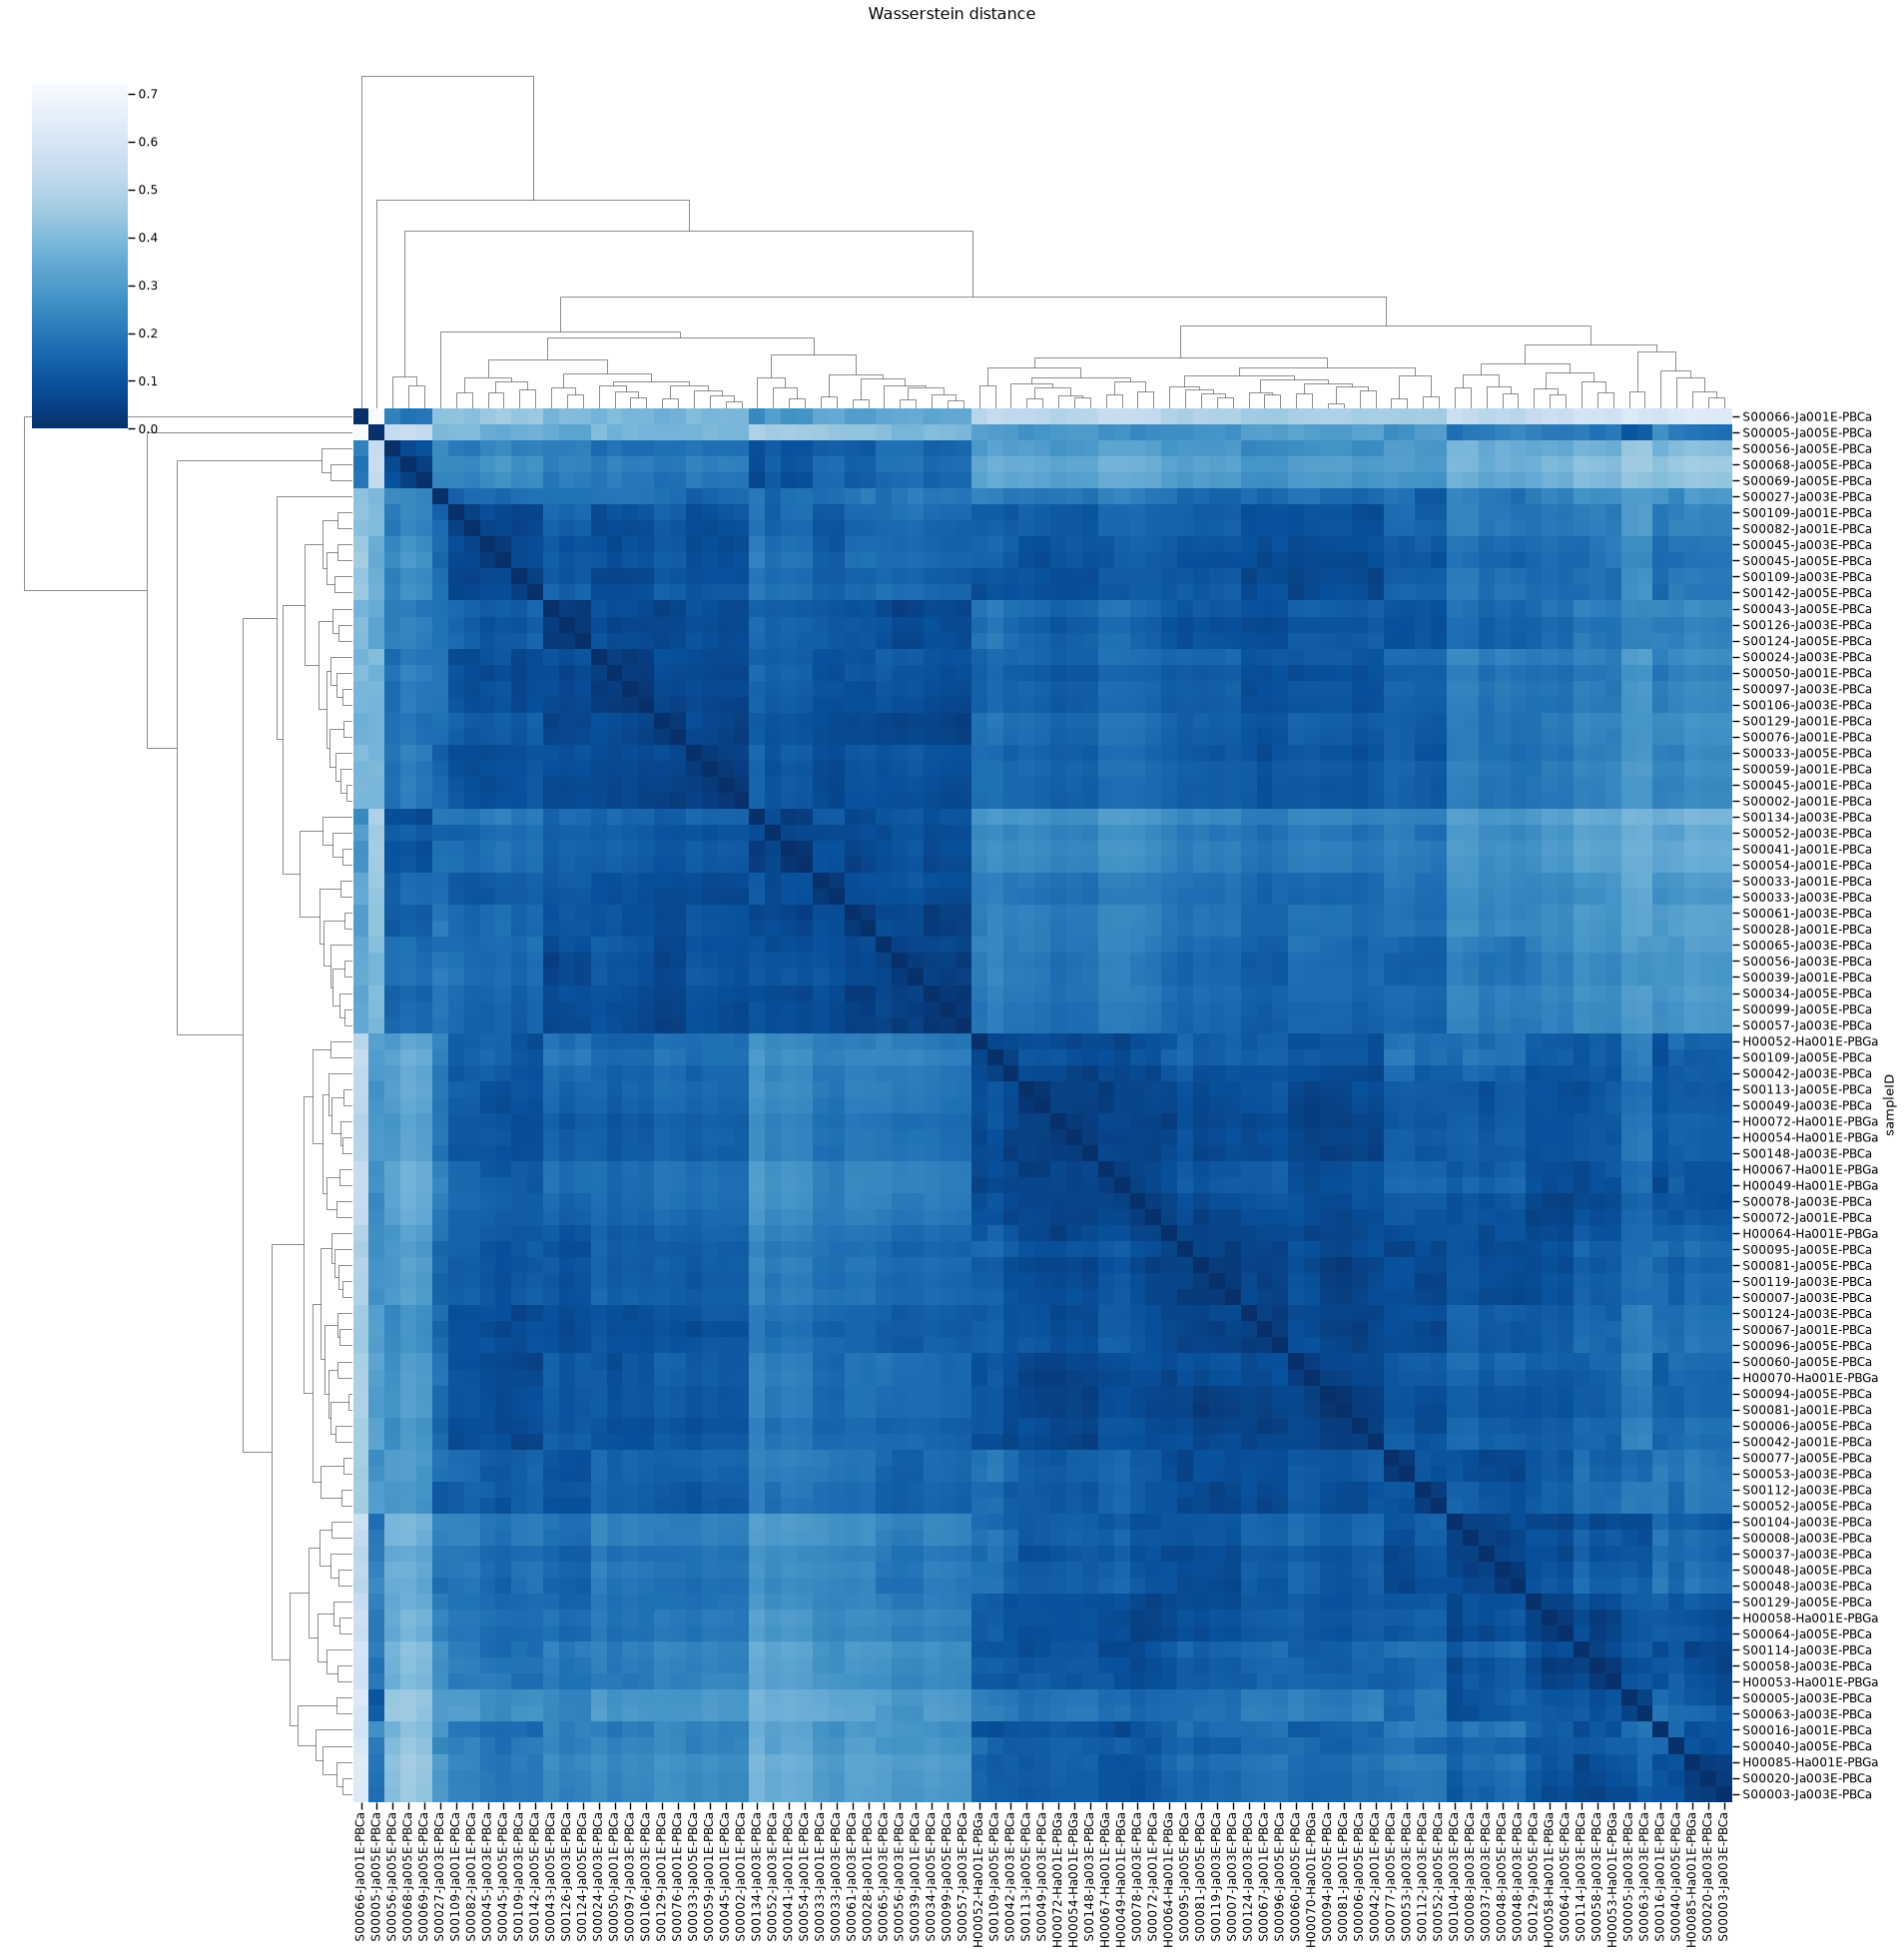

In [ ]:
pl.pl.heatmap_wasserstein(adata)

##### Trajectory and UMAP of the samples:
<div class="alert alert-block alert-info">
The trajectory is a diffusion map of the Wasserstein distances. `n_neighbors` sets how many neighbors of each sample are used. The default (64) suits large cohorts; with 87 samples we use 12, so that the trajectory follows the local structure and is not dominated by a single outlier sample.
</div>

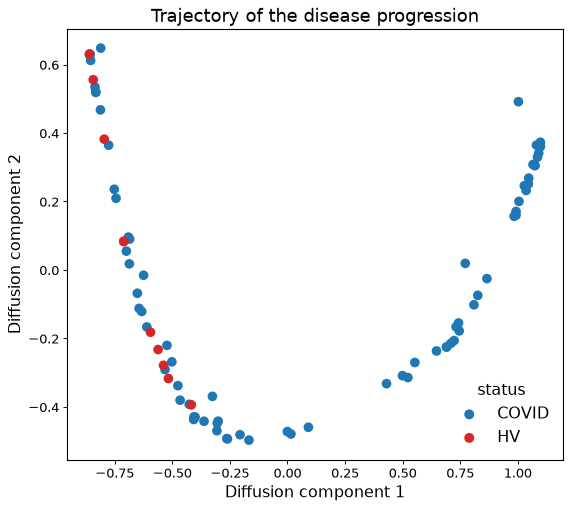

In [ ]:
pl.pl.trajectory(adata, n_neighbors = 12, colors = ['#1f77b4', '#d62728'])

<Axes: title={'center': 'UMAP of samples'}, xlabel='UMAP 1', ylabel='UMAP 2'>

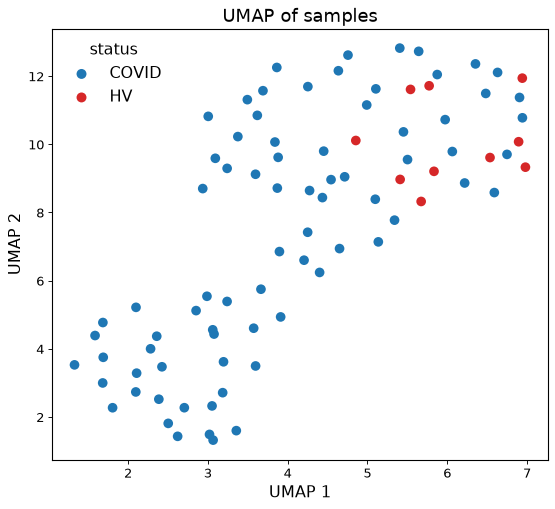

In [ ]:
pl.pl.umap_samples(adata)

##### Principal graph:
<div class="alert alert-block alert-info">
The principal graph orders the samples along the trajectory, starting at the healthy volunteers (`root_status = 'HV'`).
</div>

Root of the trajectory: node 0 (end node where the control samples come first).

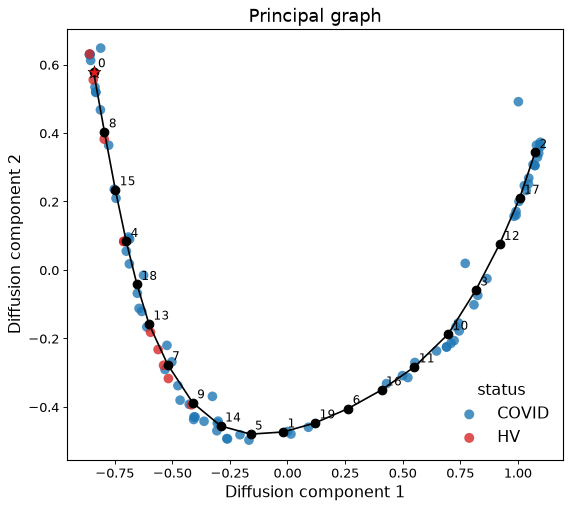

In [ ]:
pl.pl.fit_pricipla_graph(adata, source_node = 'auto', root_status = 'HV')

##### Cell type importance:
<div class="alert alert-block alert-info">
For each cell type, PILOT fits its proportion along the trajectory and tests if it changes. The heatmap shows the proportions of the samples (rows, from HV to the most severe COVID samples); the grid shows the cell types sorted by p-value.
</div>

In [ ]:
pl.tl.cell_importance_calculation(adata)

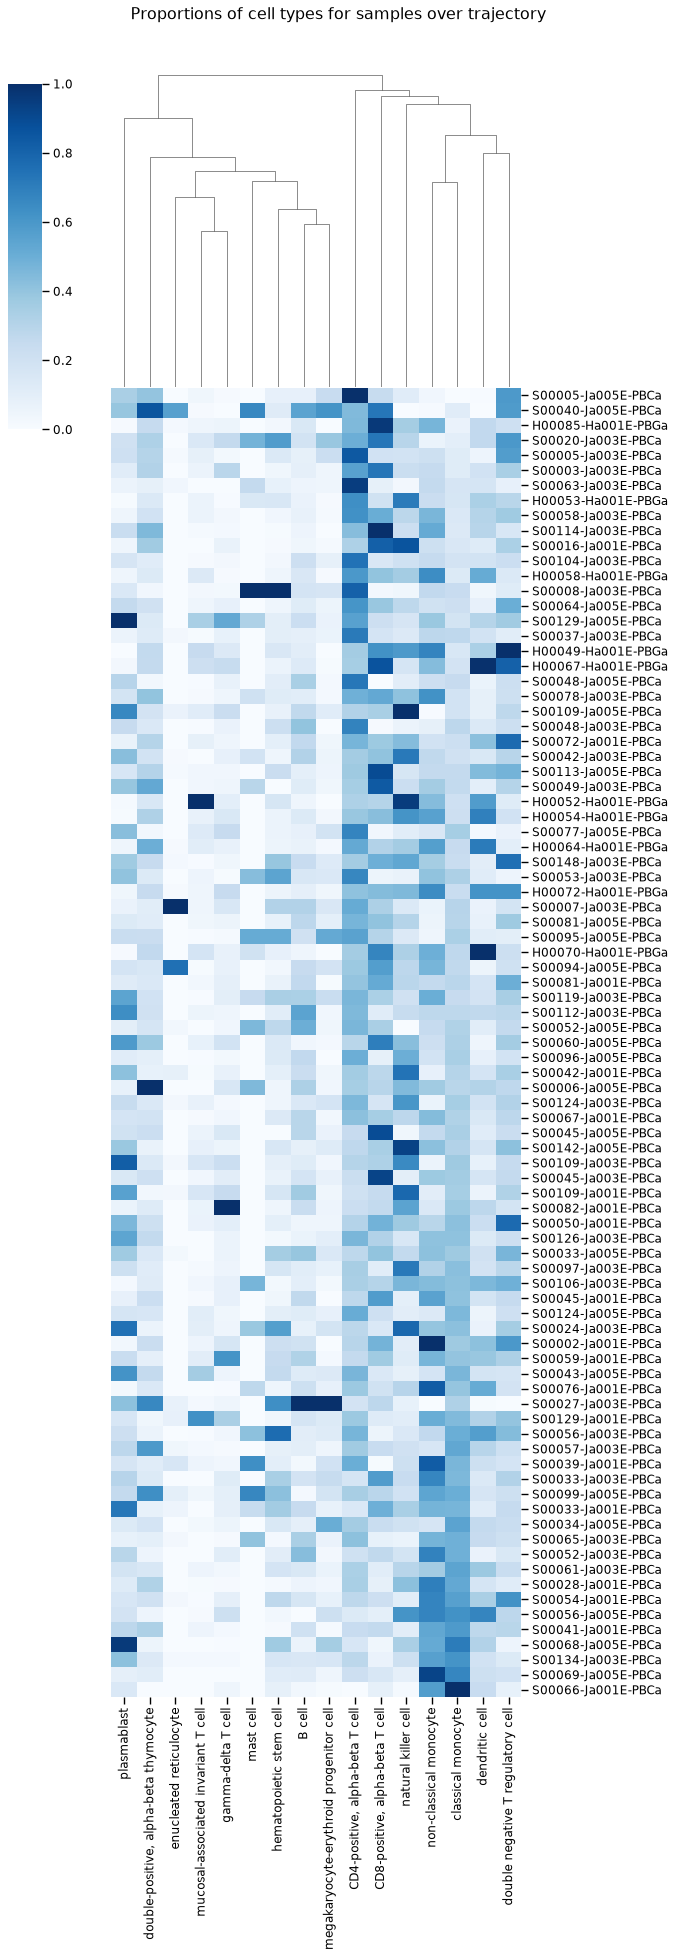

In [ ]:
pl.pl.heatmap_proportions(adata)

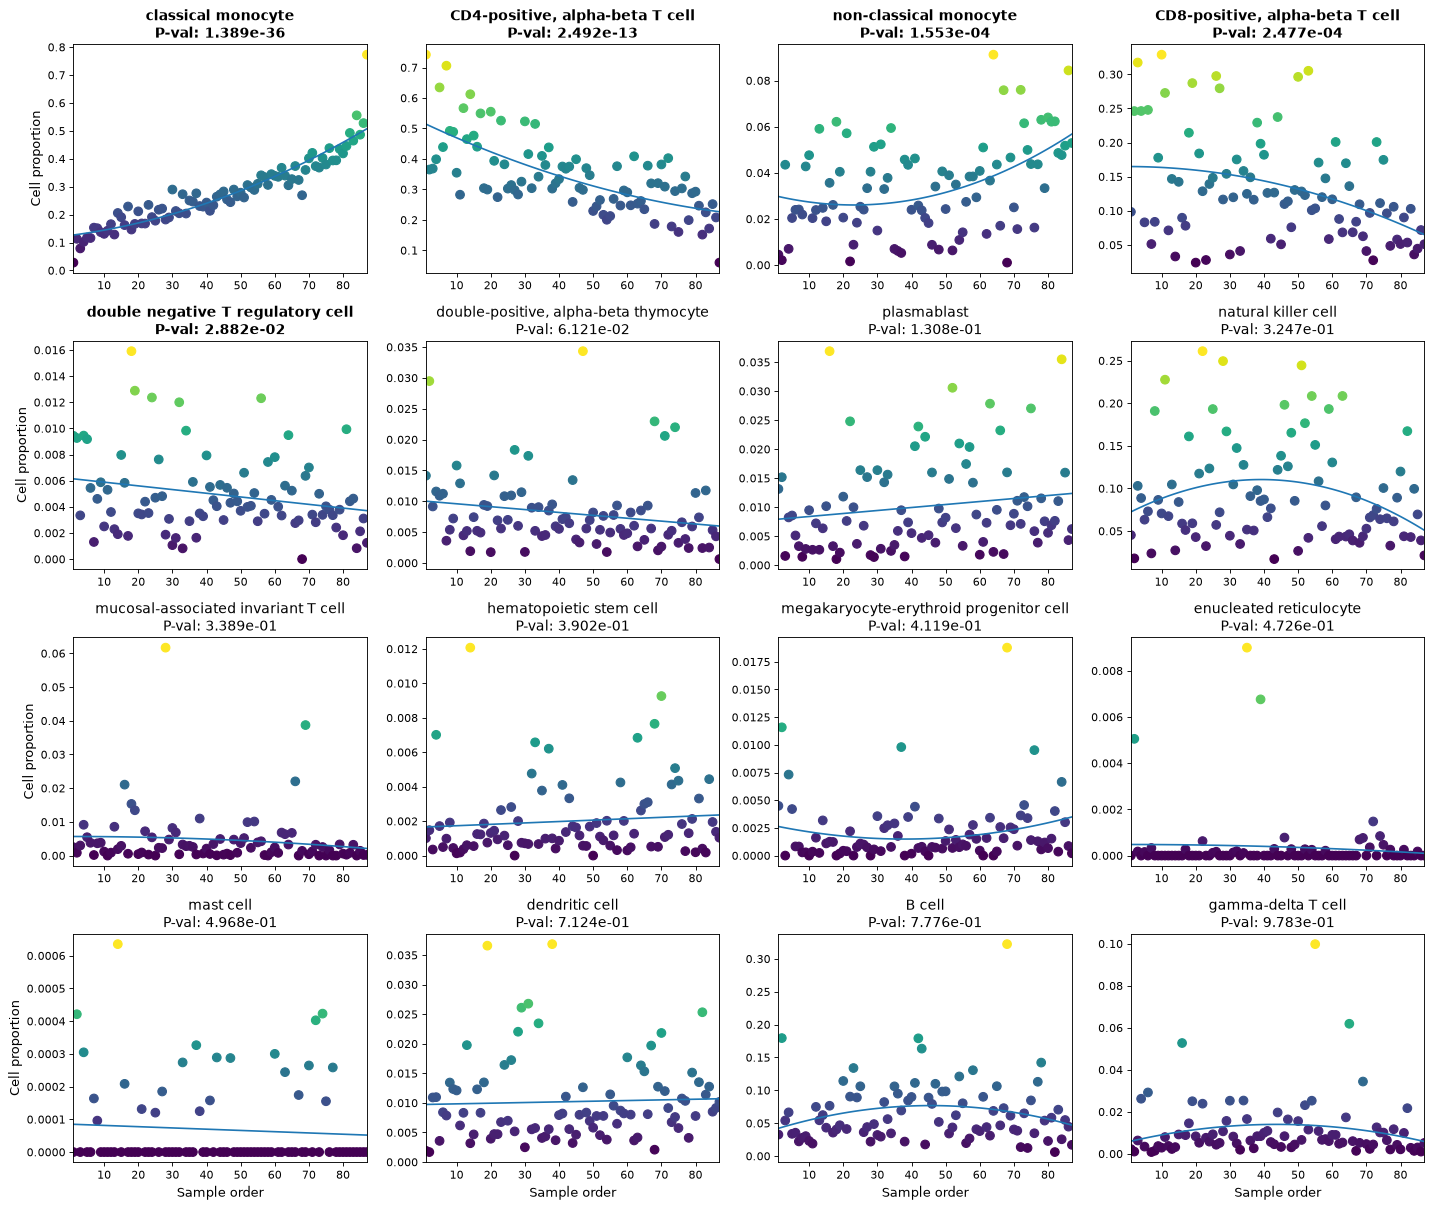

In [ ]:
pl.pl.cell_importance_grid(adata)

##### Clinical variables and the trajectory:
<div class="alert alert-block alert-info">
Which clinical (or technical) variables are related to the trajectory? `pl.tl.correlation_with_trajectory` checks **all** columns of `adata.obs` automatically:

- it keeps the variables with one value per sample (age, sex, outcome, ...) and the numeric cell-level values summarised per sample (e.g. the mean number of genes per cell);
- it detects if a variable is categorical or numeric;
- it skips columns that cannot be used (one value only, a different value for every sample such as IDs, too many missing values) and says why;
- it tests categorical variables with ANOVA and numeric variables with a Spearman correlation, and corrects the p-values for multiple testing (Benjamini-Hochberg).
</div>

In [ ]:
res = pl.tl.correlation_with_trajectory(adata)
res

Tested 30 variables (13 categorical, 17 numeric); skipped 34 columns.
  skipped (differs between the cells of a sample (cell-level)): GEX_region, cluster, cluster_source, minor_subset, minor_subset_source, major_subset, major_subset_source, cell_type_source, ...
  skipped (only one value): Institute, Symptomatic, suspension_type, tissue_type, is_primary_data, assay, tissue, assay_ontology_term_id, ...
  skipped (same groups as 'Age'): development_stage, development_stage_ontology_term_id
  skipped (same groups as 'Source'): group4
  skipped (same groups as 'group2'): PreExistingKidneyDisease, SARSCoV2PCR, disease, disease_ontology_term_id
  skipped (same groups as 'sex'): sex_ontology_term_id
  skipped (too many different values (73 for 87 samples, e.g. an ID)): donor_id
  skipped (too many missing values (52 of 87)): BMI
  skipped (too many missing values (87 of 87)): self_reported_ethnicity, self_reported_ethnicity_ontology_term_id

,Feature,Type,Level,Test,Statistic,P_value,Adjusted_P_value,Kruskal_P_value,N_samples,N_groups,Note
0,pct_counts_ribo,numeric,cell (mean),Spearman,-0.622221,1.249476e-10,3.748428e-09,NaN,87,87,
1,total_counts_ribo,numeric,cell (mean),Spearman,-0.396315,1.447238e-04,2.170857e-03,NaN,87,87,
2,PreExistingHeartDisease,categorical,sample,ANOVA,12.570288,6.401695e-04,5.779355e-03,0.000873,87,2,
3,PreExistingImmunocompromised,categorical,sample,ANOVA,12.173259,7.705807e-04,5.779355e-03,0.001030,87,2,
4,QC_scrub_doublet_scores,numeric,cell (mean),Spearman,-0.345648,1.041593e-03,6.249556e-03,NaN,87,87,
5,Source,categorical,sample,ANOVA,5.324831,2.095690e-03,1.047845e-02,0.003073,87,4,
6,Outcome,categorical,sample,ANOVA,3.954991,2.930054e-03,1.137332e-02,0.004742,87,6,
7,group2,categorical,sample,ANOVA,9.314894,3.032886e-03,1.137332e-02,0.003564,87,2,
8,PreExistingHypertension,categorical,sample,ANOVA,6.558607,1.220352e-02,4.067841e-02,0.013064,87,2,
9,Age,categorical,sample,ANOVA,2.546556,2.039536e-02,6.118608e-02,0.026688,87,8,


<div class="alert alert-block alert-info">
How to read the table:

- `Type` and `Level` say how each variable was used: 'sample' (one value per sample) or 'cell (mean)' (a per-cell value averaged per sample, e.g. QC values such as `pct_counts_ribo`).
- The skipped columns are printed above with the reason, e.g. `donor_id` (an ID), `BMI` (too many missing values) or `disease` (same groups as `group2`).
- Technical values can also be associated with the trajectory. Here the percentage of ribosomal reads (`pct_counts_ribo`) decreases along the trajectory; this can be technical, or biological (e.g. fewer lymphocytes in severe COVID-19). Such variables are worth checking.
- In this data file, all healthy volunteers have the value `True` in some `PreExisting...` columns (e.g. `PreExistingKidneyDisease`), so these columns mostly separate HV from COVID-19 patients. This is why `PreExistingKidneyDisease` is skipped as having the same groups as `group2`.
</div>

##### The significant variables on the trajectory:
<div class="alert alert-block alert-info">
`pl.pl.trajectory_associations` shows the significant variables (p < 0.05, at most 6) on the trajectory, and with `basis = 'umap'` on the UMAP of the samples. Use `variables = [...]` to choose the variables yourself, and `pl.pl.trajectory_variable` for one variable in a large plot.
</div>

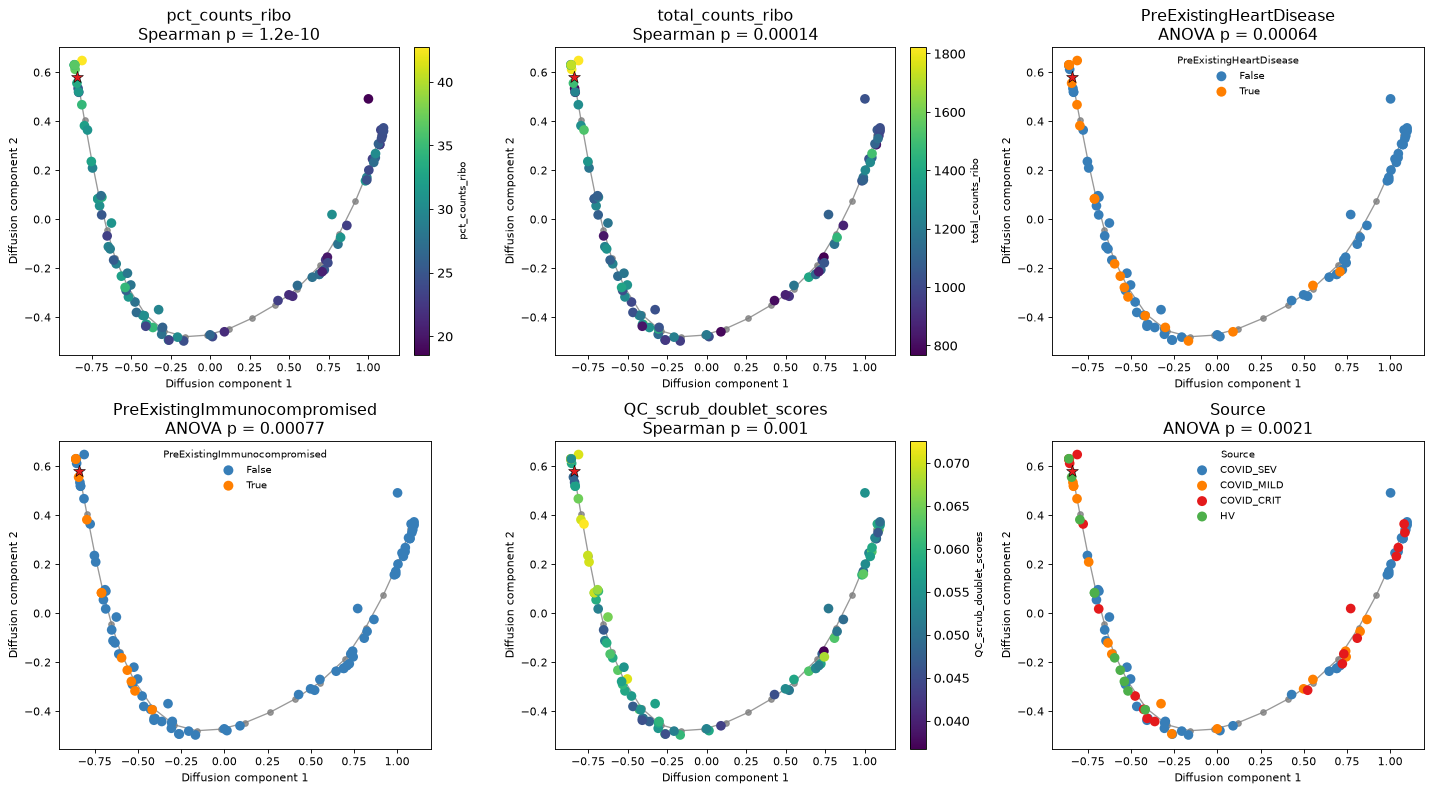

In [ ]:
pl.pl.trajectory_associations(adata)

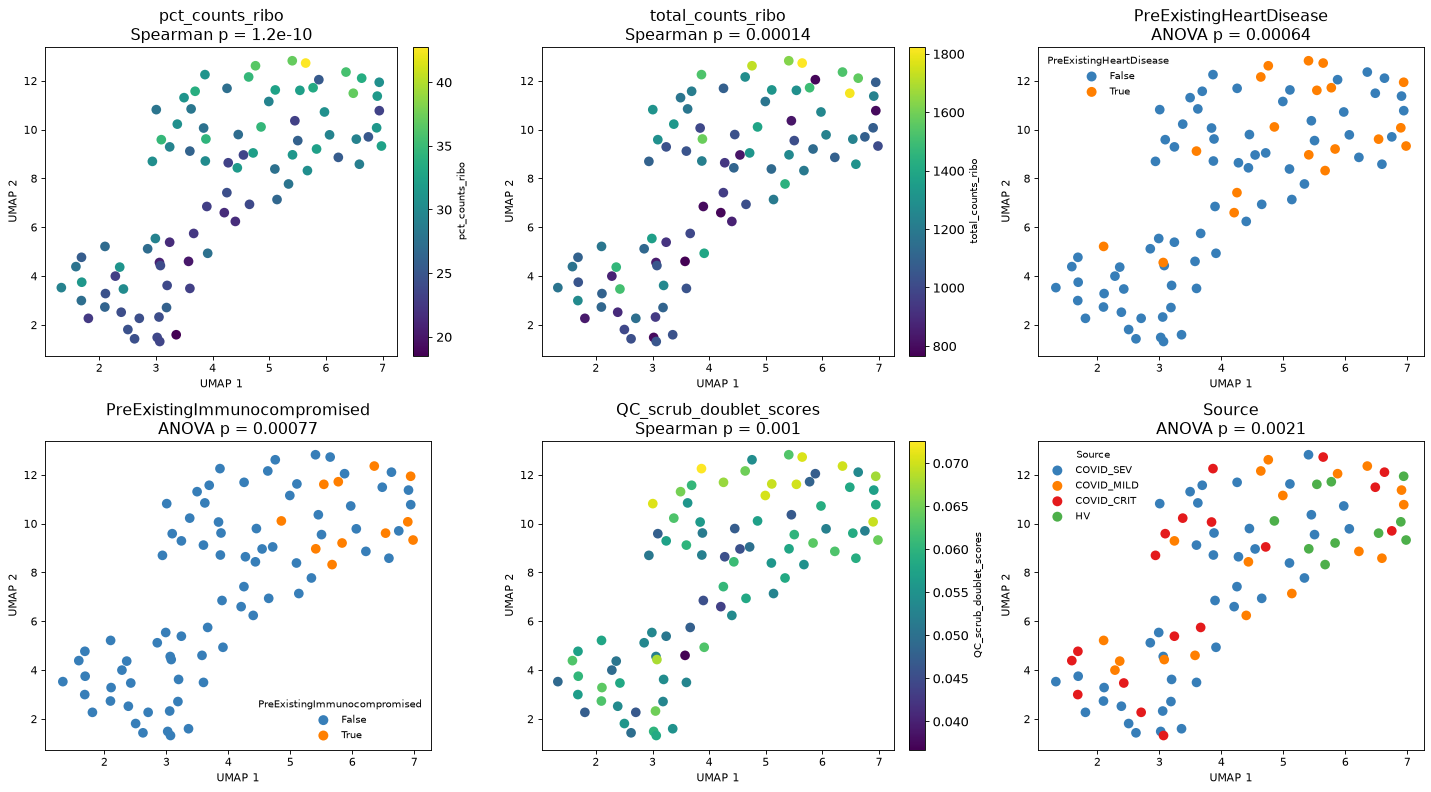

In [ ]:
pl.pl.trajectory_associations(adata, basis = 'umap')

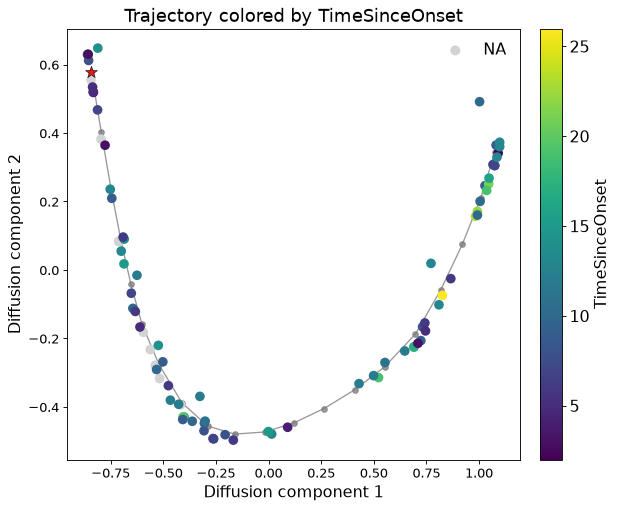

In [ ]:
pl.pl.trajectory_variable(adata, variable = 'TimeSinceOnset')

##### Four groups: HV, mild, severe and critical COVID:
<div class="alert alert-block alert-info">
The Wasserstein distances do not depend on the status, so the trajectory stays the same; with `status = 'group4'` we now see the severity of the disease and use it for the root. We repeat the steps with the four groups.
</div>

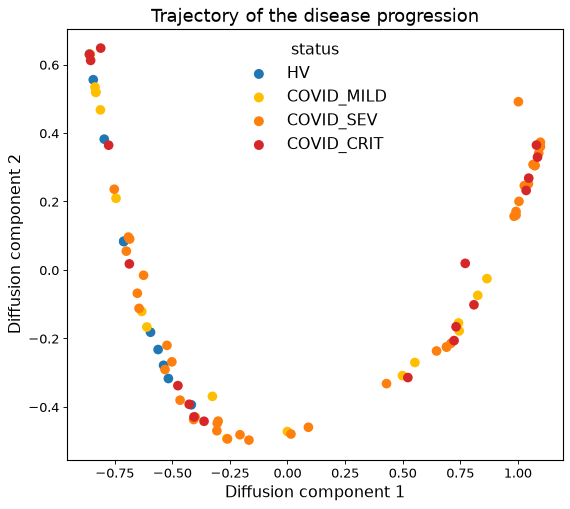

In [ ]:
pl.tl.wasserstein_distance(
    adata,
    emb_matrix = 'X_pca_harmony',
    clusters_col = 'cell_type',
    sample_col = 'scRNASeq_sample_ID',
    status = 'group4',
    )
pl.pl.trajectory(adata, n_neighbors = 12, colors = ['#1f77b4', '#ffbf00', '#ff7f0e', '#d62728'],
                 legend_order = ['HV', 'COVID_MILD', 'COVID_SEV', 'COVID_CRIT'])

<Axes: title={'center': 'UMAP of samples'}, xlabel='UMAP 1', ylabel='UMAP 2'>

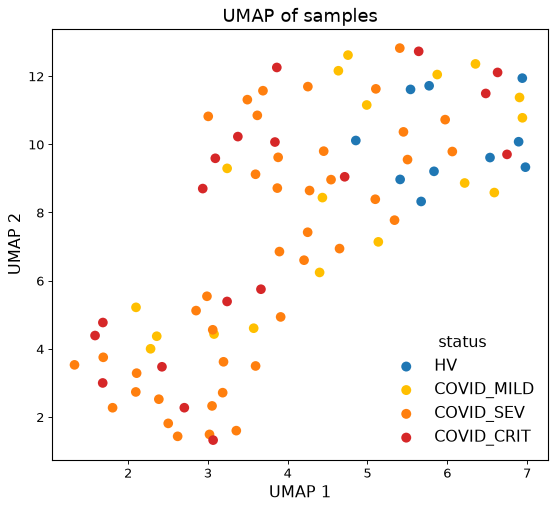

In [ ]:
pl.pl.umap_samples(adata)

Root of the trajectory: node 0 (end node where the control samples come first).

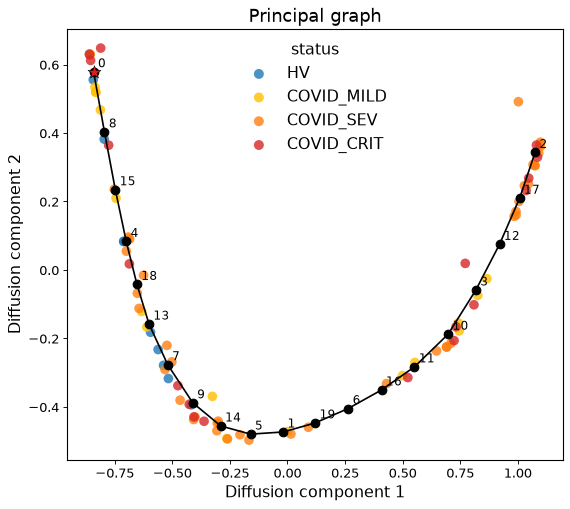

In [ ]:
pl.pl.fit_pricipla_graph(adata, source_node = 'auto', root_status = 'HV')

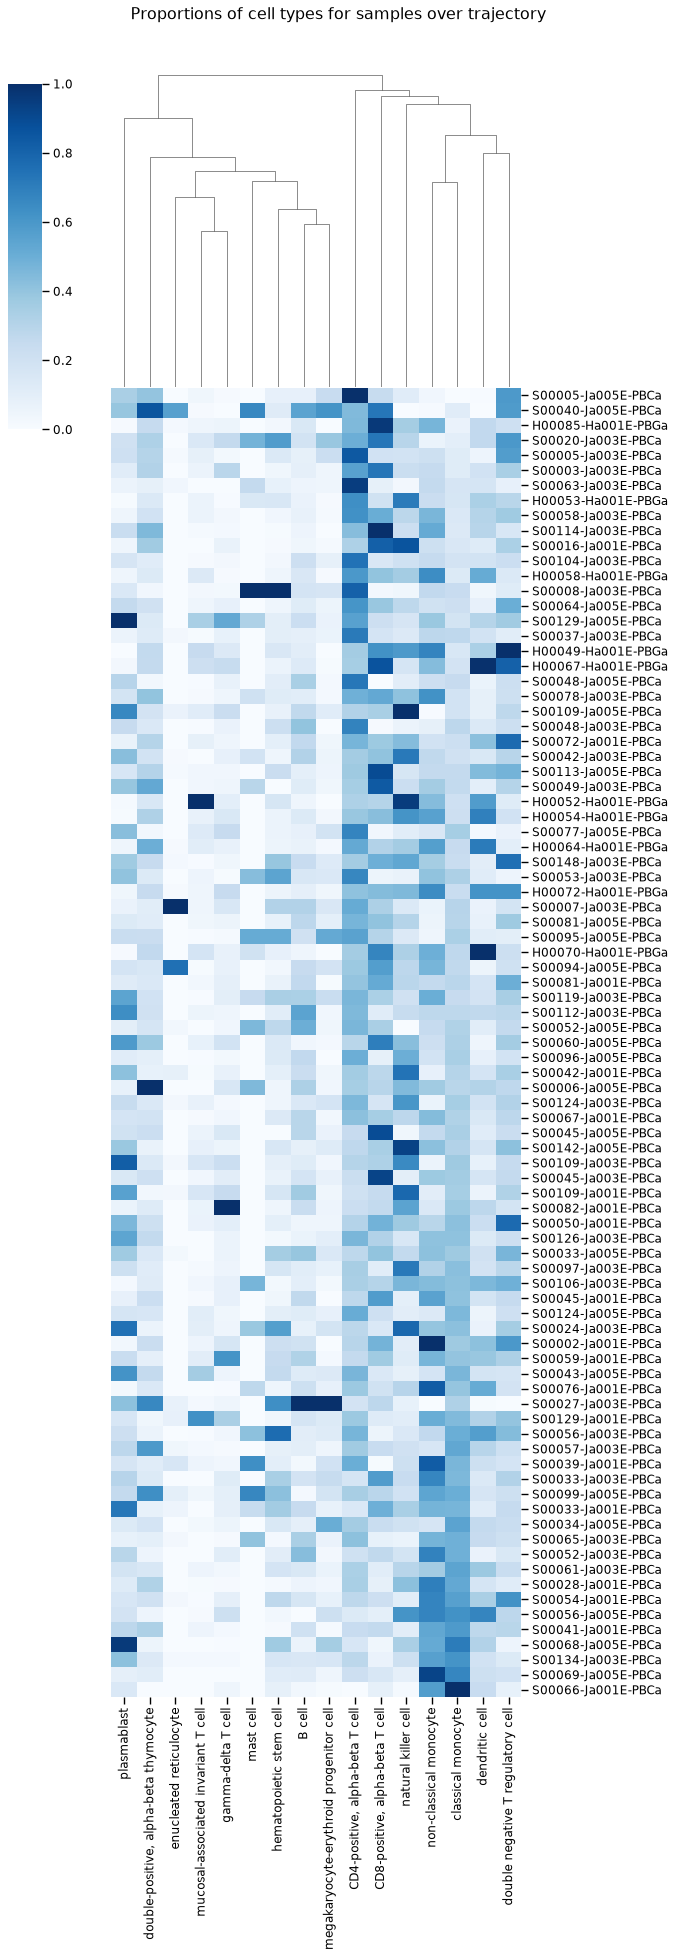

In [ ]:
pl.tl.cell_importance_calculation(adata)
pl.pl.heatmap_proportions(adata)

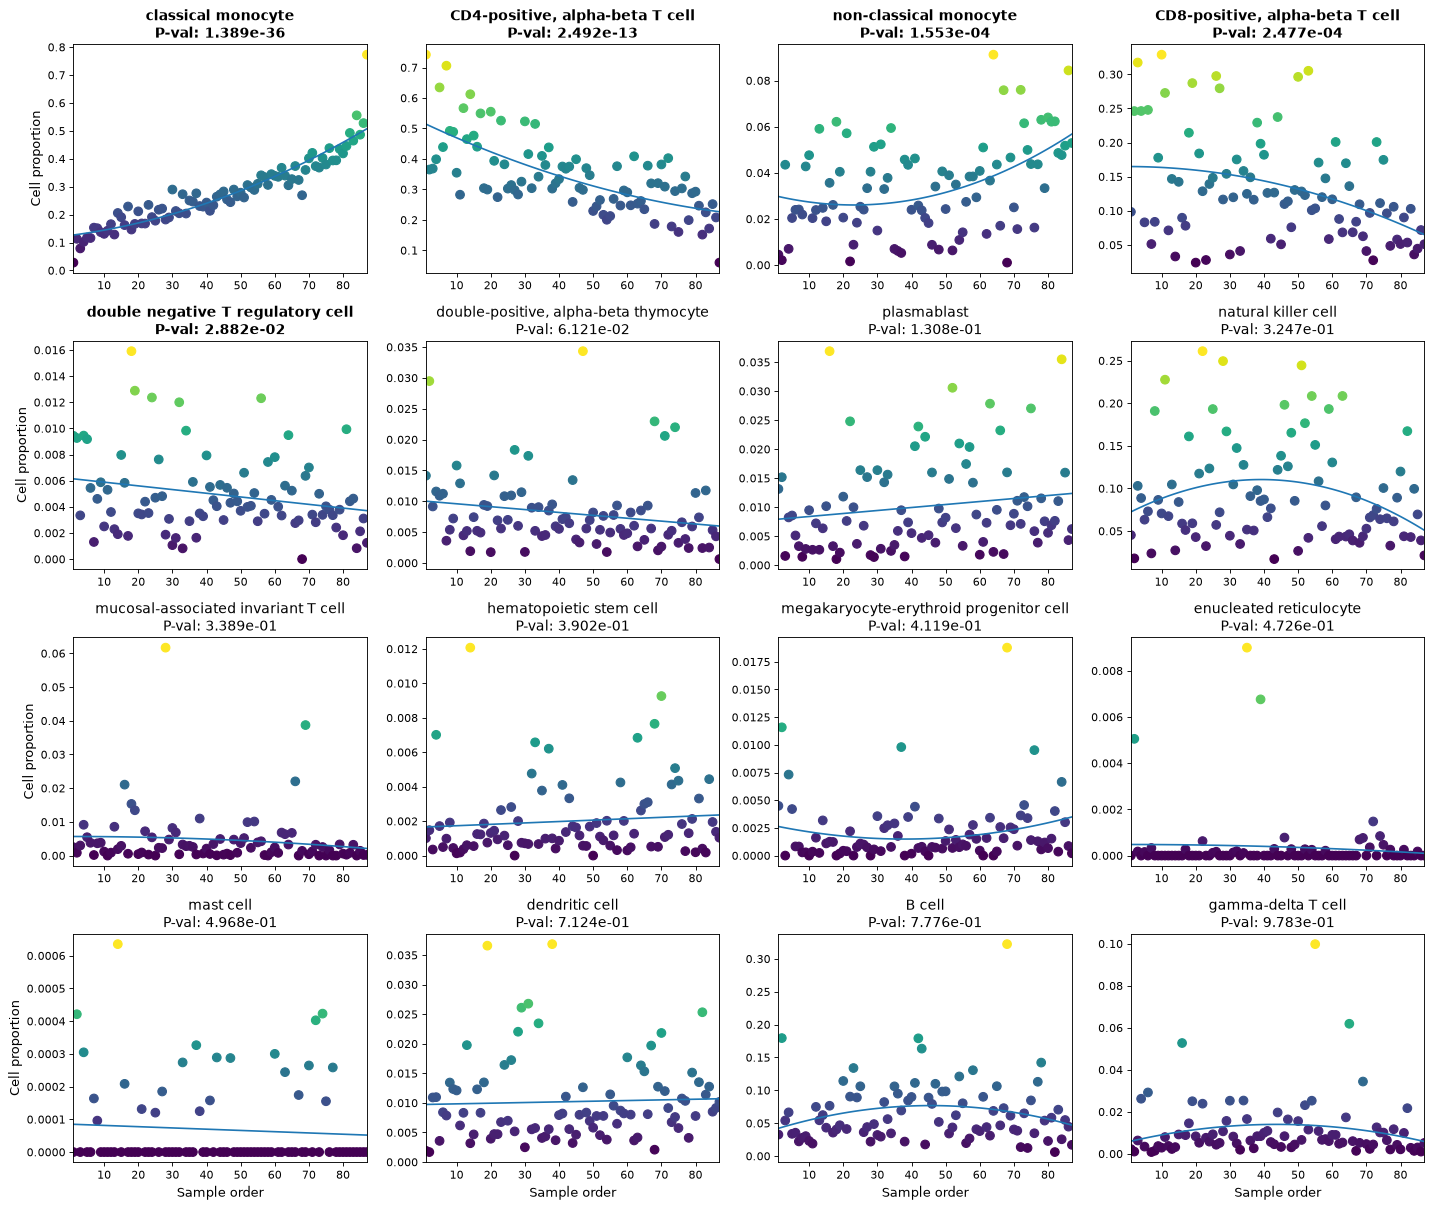

In [ ]:
pl.pl.cell_importance_grid(adata)

In [ ]:
res4 = pl.tl.correlation_with_trajectory(adata)
res4

Tested 30 variables (13 categorical, 17 numeric); skipped 34 columns.
  skipped (differs between the cells of a sample (cell-level)): GEX_region, cluster, cluster_source, minor_subset, minor_subset_source, major_subset, major_subset_source, cell_type_source, ...
  skipped (only one value): Institute, Symptomatic, suspension_type, tissue_type, is_primary_data, assay, tissue, assay_ontology_term_id, ...
  skipped (same groups as 'Age'): development_stage, development_stage_ontology_term_id
  skipped (same groups as 'PreExistingKidneyDisease'): SARSCoV2PCR, disease, group2, disease_ontology_term_id
  skipped (same groups as 'group4'): Source
  skipped (same groups as 'sex'): sex_ontology_term_id
  skipped (too many different values (73 for 87 samples, e.g. an ID)): donor_id
  skipped (too many missing values (52 of 87)): BMI
  skipped (too many missing values (87 of 87)): self_reported_ethnicity, self_reported_ethnicity_ontology_term_id

,Feature,Type,Level,Test,Statistic,P_value,Adjusted_P_value,Kruskal_P_value,N_samples,N_groups,Note
0,pct_counts_ribo,numeric,cell (mean),Spearman,-0.622221,1.249476e-10,3.748428e-09,NaN,87,87,
1,total_counts_ribo,numeric,cell (mean),Spearman,-0.396315,1.447238e-04,2.170857e-03,NaN,87,87,
2,PreExistingHeartDisease,categorical,sample,ANOVA,12.570288,6.401695e-04,5.779355e-03,0.000873,87,2,
3,PreExistingImmunocompromised,categorical,sample,ANOVA,12.173259,7.705807e-04,5.779355e-03,0.001030,87,2,
4,QC_scrub_doublet_scores,numeric,cell (mean),Spearman,-0.345648,1.041593e-03,6.249556e-03,NaN,87,87,
5,group4,categorical,sample,ANOVA,5.324831,2.095690e-03,1.047845e-02,0.003073,87,4,
6,Outcome,categorical,sample,ANOVA,3.954991,2.930054e-03,1.137332e-02,0.004742,87,6,
7,PreExistingKidneyDisease,categorical,sample,ANOVA,9.314894,3.032886e-03,1.137332e-02,0.003564,87,2,
8,PreExistingHypertension,categorical,sample,ANOVA,6.558607,1.220352e-02,4.067841e-02,0.013064,87,2,
9,Age,categorical,sample,ANOVA,2.546556,2.039536e-02,6.118608e-02,0.026688,87,8,


<div class="alert alert-block alert-info">
With four groups, the severity (`group4`) and the `Outcome` of the patients are associated with the trajectory, together with the same technical and `PreExisting...` variables as above. Because `group4` is now the status, `group2` and `disease` are reported as copies of `PreExistingKidneyDisease` (see the note above).
</div>

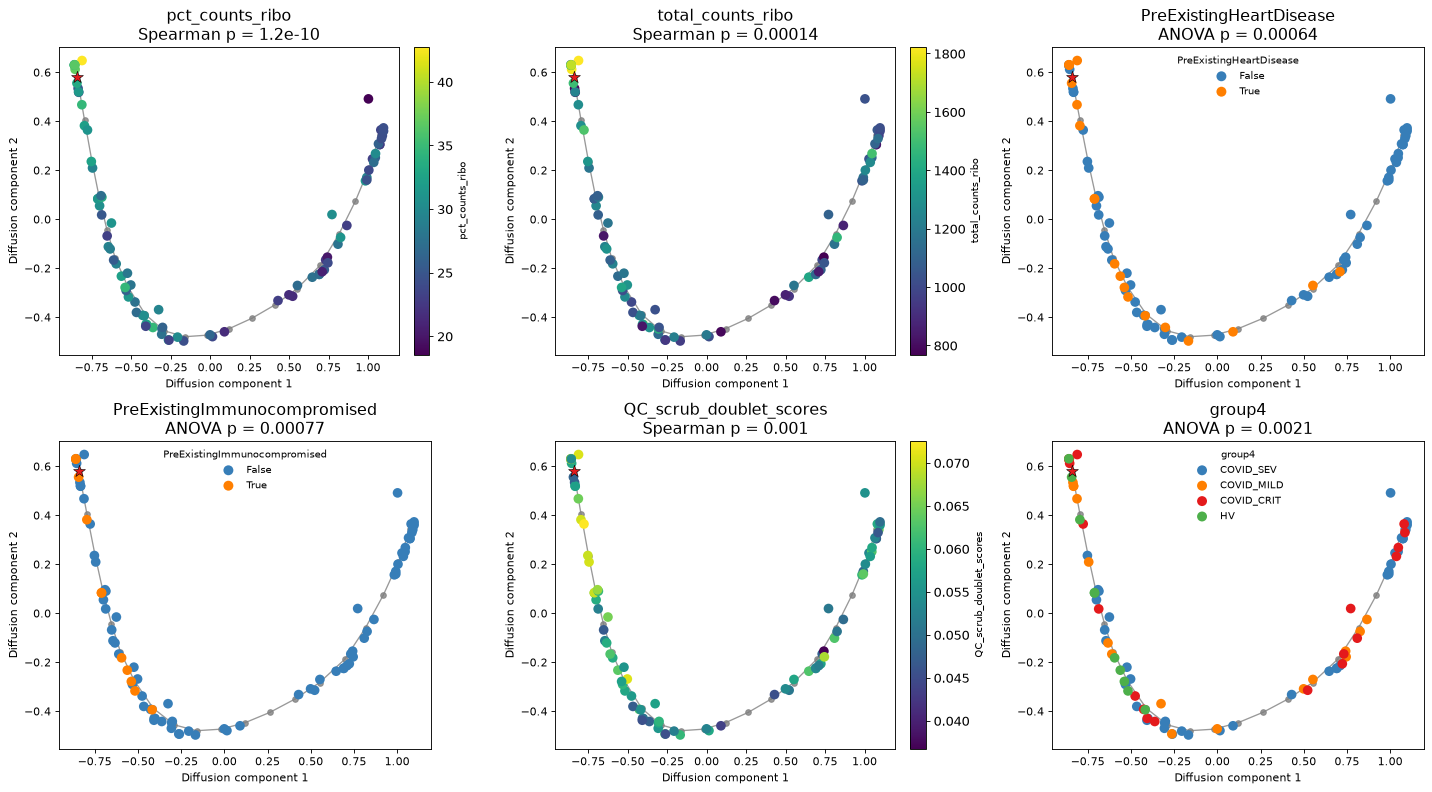

In [ ]:
pl.pl.trajectory_associations(adata)

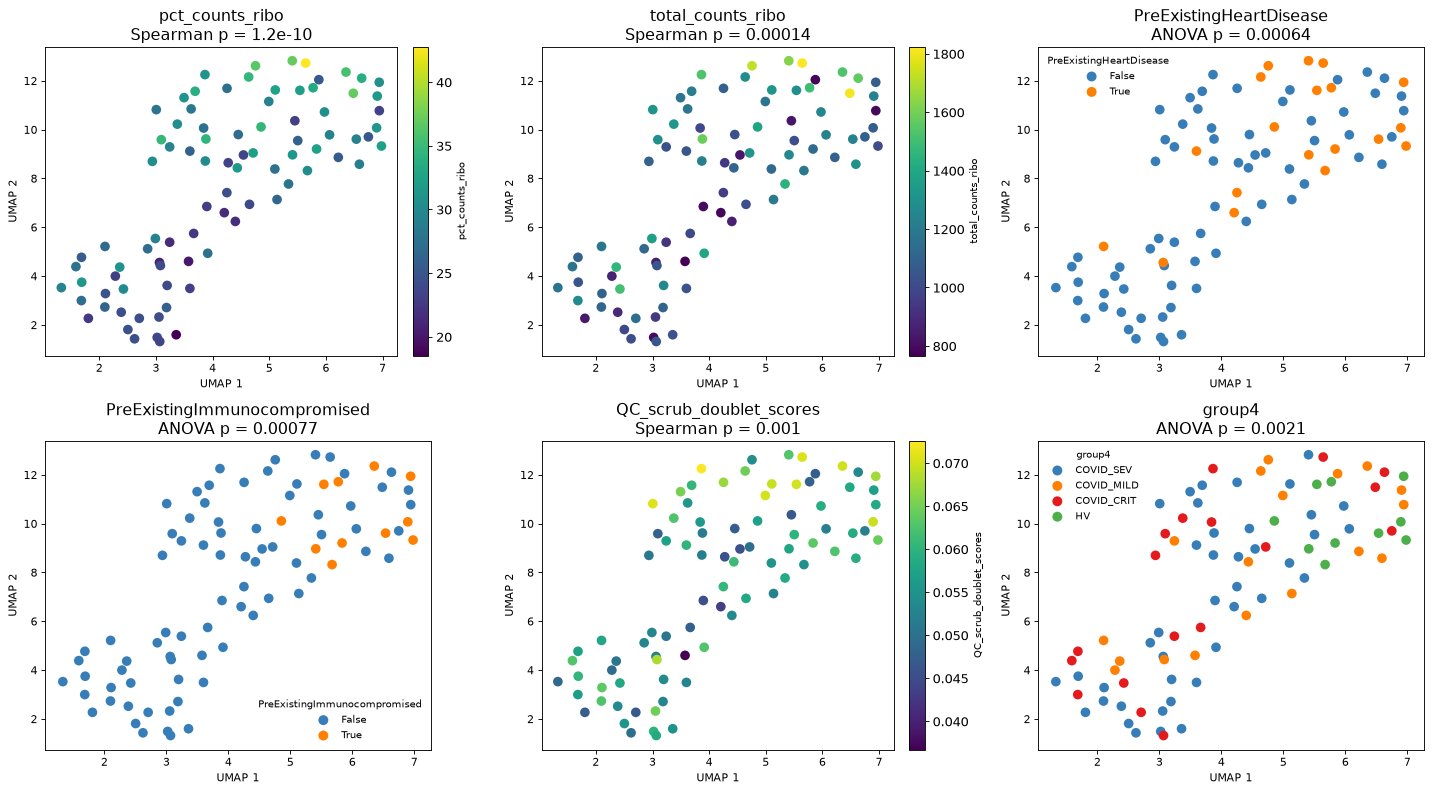

In [ ]:
pl.pl.trajectory_associations(adata, basis = 'umap')

<div class="alert alert-block alert-info">
<b>Next steps</b>

From here, all other PILOT analyses work as in the other tutorials, for example the genes of the important cell types (`pl.tl.genes_importance`, see the [Myocardial Infarction tutorial](https://pilot.readthedocs.io/en/latest/Myocardial_infarction.html)), branches of the trajectory ([Trajectory branches](https://pilot.readthedocs.io/en/latest/Trajectory_branches.html)) or sub-groups of patients ([Patients sub-group detection](https://pilot.readthedocs.io/en/latest/Patients_sub_group_detection.html)).
</div>